# Part 4 — CNN Classification
Balance via Part 2 · Train CNN · Evaluate with f1-score

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import re

# silent warnings
import warnings
from src.augmentation import LeafAugmenter
from src.data import LeafLoader
from src.model import LeafClassifier

warnings.filterwarnings("ignore", category=UserWarning, module="tensorflow")

/home/samy/miniconda3/envs/tf-gpu/lib/python3.11/site-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info The read operation timed out
  data = fetch_version_info()
2026-08-27 21:04:07.777465: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-27 21:04:07.806451: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-08-27 21:04:08.428074: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors 

In [2]:
root = Path("..")
output_dir = str(root / "augmented_directory")
augmented_dir = Path(output_dir)

In [3]:
print("Balancing dataset...")
loader = LeafLoader()
augmenter = LeafAugmenter(loader=loader)
print("Before:", loader.counts)
augmenter.balance_dataset(
    loader.images, max_len=loader.majority_count, out_dir=str(augmented_dir)
)
balanced = LeafLoader(data_path=augmented_dir)
print("After:", balanced.counts)

Balancing dataset...
Before: {'Grape_healthy': 422, 'Apple_healthy': 1646, 'Grape_Esca': 1382, 'Apple_rust': 275, 'Apple_Black_rot': 620, 'Grape_Black_rot': 1178, 'Apple_scab': 629, 'Grape_spot': 1075}
After: {'Grape_healthy': 1646, 'Apple_healthy': 1646, 'Grape_Esca': 1646, 'Apple_rust': 1646, 'Apple_Black_rot': 1646, 'Grape_Black_rot': 1646, 'Apple_scab': 1646, 'Grape_spot': 1646}


In [4]:
EPOCHS = 10
TARGET_ACC = 0.90
PATIENCE = 10

print(f"\nTraining CNN...")
classifier = LeafClassifier()
m, history, train_ds, val_ds, test_ds, classnames = classifier.train(
    train_dir=output_dir,
    epochs=EPOCHS,
    target_acc=TARGET_ACC,
    patience=PATIENCE,
)


Training CNN...
Found 13168 files belonging to 8 classes.
Using 10535 files for training.
Using 2633 files for validation.


I0000 00:00:1787861095.702059  123101 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6148 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Classes (8): ['Apple_Black_rot', 'Apple_healthy', 'Apple_rust', 'Apple_scab', 'Grape_Black_rot', 'Grape_Esca', 'Grape_healthy', 'Grape_spot']
Epoch 1/10


2026-08-27 21:05:00.170336: I external/local_xla/xla/service/service.cc:163] XLA service 0x7fa018002690 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-08-27 21:05:00.170357: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4070 Laptop GPU, Compute Capability 8.9
2026-08-27 21:05:00.236776: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-08-27 21:05:01.843435: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92400
2026-08-27 21:05:01.942007: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-08-27 21:05:04.

 11/297 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.3068 - loss: 2.4640

I0000 00:00:1787861106.893303  123995 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


... (5 outputs left out)

2026-08-27 21:05:59.663378: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



Per-class F1: Apple_Black_rot=0.970, Apple_healthy=0.981, Apple_rust=0.988, Apple_scab=0.953, Grape_Black_rot=0.875, Grape_Esca=0.858, Grape_healthy=0.990, Grape_spot=0.977
Worst class: Grape_Esca (0.8581)
297/297 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.9500 - loss: 0.1318 - val_accuracy: 0.9495 - val_loss: 0.1334 - val_f1_Apple_Black_rot: 0.9702 - val_f1_Apple_healthy: 0.9814 - val_f1_Apple_rust: 0.9876 - val_f1_Apple_scab: 0.9527 - val_f1_Grape_Black_rot: 0.8747 - val_f1_Grape_Esca: 0.8581 - val_f1_Grape_healthy: 0.9903 - val_f1_Grape_spot: 0.9774
Epoch 5/10
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9617 - loss: 0.0991
Per-class F1: Apple_Black_rot=0.972, Apple_healthy=0.984, Apple_rust=0.985, Apple_scab=0.953, Grape_Black_rot=0.858, Grape_Esca=0.877, Grape_healthy=0.989, Grape_spot=0.977
Worst class: Grape_Black_rot (0.8576)
297/297 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.9617 - loss: 0.0992 - val_accuracy: 0.9495 - val_loss: 0.1378 - val_f1_Apple_Bl

2026-08-27 21:06:45.251915: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



Per-class F1: Apple_Black_rot=0.972, Apple_healthy=0.980, Apple_rust=0.981, Apple_scab=0.953, Grape_Black_rot=0.876, Grape_Esca=0.874, Grape_healthy=0.992, Grape_spot=0.967
Worst class: Grape_Esca (0.8735)
297/297 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - accuracy: 0.9608 - loss: 0.0998 - val_accuracy: 0.9495 - val_loss: 0.1460 - val_f1_Apple_Black_rot: 0.9717 - val_f1_Apple_healthy: 0.9797 - val_f1_Apple_rust: 0.9812 - val_f1_Apple_scab: 0.9531 - val_f1_Grape_Black_rot: 0.8764 - val_f1_Grape_Esca: 0.8735 - val_f1_Grape_healthy: 0.9916 - val_f1_Grape_spot: 0.9673
Epoch 9/10
296/297 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9718 - loss: 0.0779
Per-class F1: Apple_Black_rot=0.968, Apple_healthy=0.977, Apple_rust=0.988, Apple_scab=0.950, Grape_Black_rot=0.898, Grape_Esca=0.917, Grape_healthy=0.979, Grape_spot=0.980
Worst class: Grape_Black_rot (0.8981)
297/297 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - accuracy: 0.9718 - loss: 0.0779 - val_accuracy: 0.9571 - val_loss: 0.1374 - val_f1_Apple_Bl

In [5]:
print("\nEvaluating validation split...")
classifier.evaluate(val_ds)

print("\nEvaluating held-out test split (returned from load_datasets, unseen from training)...")
classifier.evaluate(test_ds)


Evaluating validation split...
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step

Accuracy: 0.9502  (target: >95%)

                 precision    recall  f1-score   support

Apple_Black_rot       0.96      0.97      0.97       320
  Apple_healthy       0.95      0.99      0.97       317
     Apple_rust       0.97      0.99      0.98       324
     Apple_scab       0.98      0.90      0.94       320
Grape_Black_rot       0.85      0.94      0.89       355
     Grape_Esca       0.94      0.83      0.88       311
  Grape_healthy       0.98      0.99      0.98       358
     Grape_spot       0.98      0.98      0.98       328

       accuracy                           0.95      2633
      macro avg       0.95      0.95      0.95      2633
   weighted avg       0.95      0.95      0.95      2633


Evaluating held-out test split (returned from load_datasets, unseen from training)...
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step

Accuracy: 0.1250  (target: >95%)

                 precision    recall  f1-sco

(np.float64(0.125),
 array([3, 3, 6, ..., 7, 1, 4], shape=(1056,), dtype=int32),
 array([7, 7, 4, ..., 1, 7, 0], shape=(1056,)),
 array([[21, 17, 25, 11, 13, 12, 20, 19],
        [ 8, 23, 13, 15, 20, 20, 19, 19],
        [21, 25, 13, 19, 21, 20, 15,  9],
        [19, 19, 16, 11, 21, 12, 12, 21],
        [16, 14, 12, 15, 17, 10, 16, 16],
        [18, 12, 17, 22, 19, 16, 19, 15],
        [16, 12, 22, 22, 13, 14,  9, 11],
        [15, 14, 23, 18, 16, 11, 15, 22]]))

[PosixPath('../test/Unit_test1'), PosixPath('../test/Unit_test2')]
True
True

Found 10 test images

Test accuracy: 100.00%  (10/10)

                 precision    recall  f1-score   support

Apple_Black_rot       1.00      1.00      1.00         1
  Apple_healthy       1.00      1.00      1.00         2
     Apple_rust       1.00      1.00      1.00         1
     Apple_scab       1.00      1.00      1.00         1
Grape_Black_rot       1.00      1.00      1.00         2
     Grape_Esca       1.00      1.00      1.00         1
  Grape_healthy       1.00      1.00      1.00         1
     Grape_spot       1.00      1.00      1.00         1

       accuracy                           1.00        10
      macro avg       1.00      1.00      1.00        10
   weighted avg       1.00      1.00      1.00        10

Details:
  [OK   ] Apple_Black_rot1.JPG            true=Apple_Black_rot            pred=Apple_Black_rot
  [OK   ] Apple_healthy1.JPG              true=Apple_healthy              pr

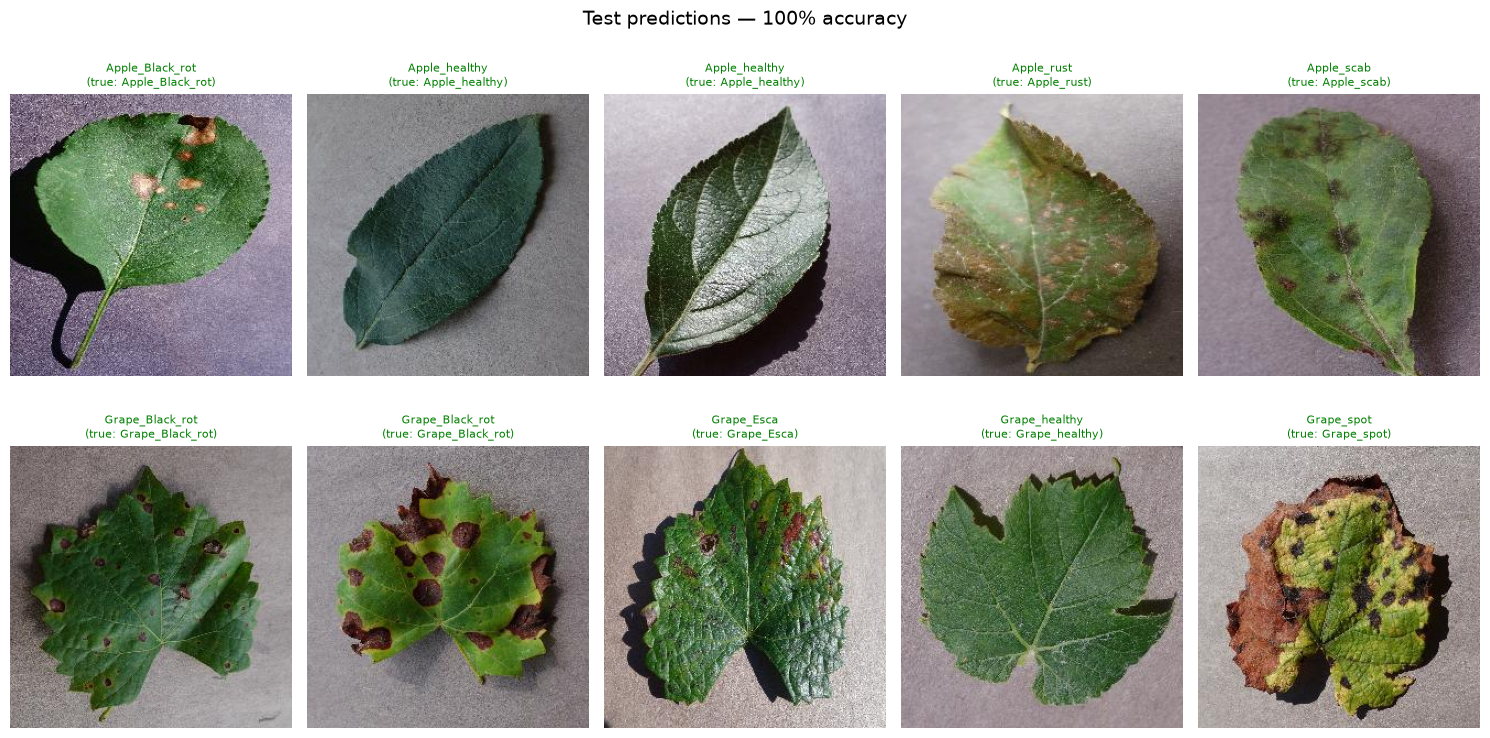

In [6]:
test_images = [root / "test" / d for d in ["Unit_test1", "Unit_test2"]]
print(test_images)

for d in test_images:
    print(d.exists())

acc, details = classifier.test_on_images(test_images)

if details:
    classifier.show_predictions(test_images, details, acc)

In [7]:
model_dir = str(root / "model")
classifier.save(out_dir=model_dir)

zip_path = classifier.zip_artifacts(
    train_dir=output_dir, model_dir=model_dir, out_zip=str(root / "model.zip")
)
classifier.sign(zip_path=zip_path, sig_file=str(root / "signature.txt"))

Model saved to ../model
Zipped → ../model.zip
Signed → ../signature.txt
  dfcd5e84cd26eac6524fc348efe53b49dd94d44d  model.zip


'dfcd5e84cd26eac6524fc348efe53b49dd94d44d  model.zip'